<div align="center">

# **DS201: LSTM, GRU và BiLSTM (LAB 03)**

**Họ và tên: Phạm Đình Quang Huy**

**MSSV: 24520689**  
</div>

## **Mục tiêu và thiết kế**
Ba bài thực nghiệm gồm LSTM 5 lớp và GRU 5 lớp để phân loại sentiment trên UIT-VSFC, và BiLSTM 5 lớp để gán nhãn thực thể trên PhoNER. Các mô hình dùng embedding 300 chiều, hidden size 256, dropout 0,3 và tối đa 10 epoch. Checkpoint được lựa chọn theo F1 trên dev rồi mới đánh giá trên test. Tất cả nhận xét trong notebook này dựa trên output đã lưu của lần chạy hiện tại; đây không phải số liệu giả lập.

Bộ so sánh TF-IDF + Logistic Regression đóng vai trò baseline. Vì bài NER và bài phân loại có khác biệt về nhãn và đơn vị đánh giá, kết quả F1 của BiLSTM NER được trình bày riêng

## **0. Chuẩn bị**
- Dữ liệu: `data/uit-vsfc/UIT-VSFC-{train,dev,test}.json` và `data/phoner/{train,dev,test}_syllable.json` (JSON Lines). Điều chỉnh đường dẫn Drive ở cell dưới nếu cần.

- Thư viện: Thực hiện import các thư viện như numpy, pandas, torch, sklearn, seqevel.

In [4]:
import copy, json, random, time
from collections import Counter
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import DataLoader
from torch.nn.utils.rnn import pad_sequence, pack_padded_sequence, pad_packed_sequence
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             classification_report, ConfusionMatrixDisplay)
from seqeval.metrics import (f1_score as entity_f1, precision_score as entity_precision,
                             recall_score as entity_recall, classification_report as entity_report)
from seqeval.metrics.sequence_labeling import get_entities
from seqeval.scheme import IOB2

PAD, UNK, PAD_TAG = 0, 1, -100
cfg = dict(emb=300, hidden=256, layers=5, dropout=0.3, batch=32, lr=1e-3, epochs=10)
def seed_all(seed=42):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)
seed_all()
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
DATA = Path('data')
ART = Path('artifacts'); ART.mkdir(exist_ok=True)
print('Thiết bị:', device, '| Cấu hình:', cfg)

Thiết bị: cuda | Cấu hình: {'emb': 300, 'hidden': 256, 'layers': 5, 'dropout': 0.3, 'batch': 32, 'lr': 0.001, 'epochs': 10}


**Lưu ý:**
- Cấu hình bắt buộc: embedding 300, hidden 256, 5 lớp, dropout 0.3, batch 32, Adam learning rate 0.001, tối đa 10 epoch và seed 42. Không sử dụng trọng số pretrained.
- `PAD=0` dùng cho token đệm, `UNK=1` cho token ngoài từ điển, `PAD_TAG=-100` để bỏ qua nhãn đệm khi tính loss NER.
- Cell `%cd` phải trỏ đến thư mục chứa `data/`. Thư mục cần có `uit-vsfc/UIT-VSFC-{train,dev,test}.json` và `phoner/{train,dev,test}_syllable.json`.

## **UIT-VSFC — Dữ liệu và hàm dùng chung**

Thực hiện đọc các file json dữ liệu đối với bộ dữ liệu VSFC và lưu vào trong distionary vsfc. Đồng thời thực hiện chuyển label của dữ liệu về dạng số để dễ thực hiện tính toán sau này.

In [5]:
LABELS = ['negative', 'neutral', 'positive']
label_to_id = {name: i for i, name in enumerate(LABELS)}
vsfc = {s: json.loads((DATA / 'uit-vsfc' / f'UIT-VSFC-{s}.json').read_text(encoding='utf-8-sig'))
        for s in ['train', 'dev', 'test']}

Cell này thực hiện các tác vụ dưới đây:
1. Chuyển chuỗi thành các token bằng hàm Tokenizer.
2. Thực hiện xây dựng bộ từ vựng cho hệ thống, gán pad=0 và unk=1

In [6]:
def tokenize(text):
    return text.lower().split()

def build_vocab(sequences, min_freq=2):
    counts = Counter(token for seq in sequences for token in seq)
    tokens = sorted(t for t, n in counts.items() if n >= min_freq)
    return {'<pad>': PAD, '<unk>': UNK, **{t: i + 2 for i, t in enumerate(tokens)}}

vocab = build_vocab(tokenize(r['sentence']) for r in vsfc['train'])

Sau đó thực hiện encode dữ liệu và tạo loader cho các file train, dev và test.

**Nhận xét:**
Output lưu trong notebook xác nhận **11.426 train, 1.583 dev, 3.166 test** và vocabulary có **1.535 token**. Từ điển được xây dựng từ train với `min_freq=2`; các token ngoài từ điển sẽ thành `<unk>`. Hàm `collate_cls` tạo padding động theo câu dài nhất trong mỗi batch và giữ `lengths` để mô hình biết độ dài chuỗi thực.

**Lưu ý:** Chỉ sử dụng `sentence` làm đầu vào và `sentiment` làm nhãn; không sử dụng `topic`. Trong bài phân loại ba lớp loại trừ nhau, nhãn được dự đoán bằng `argmax` trên logits và loss là `CrossEntropyLoss`, không thêm Softmax trong mô hình

In [7]:
def encode(tokens, vocab):
    return [vocab.get(t, UNK) for t in tokens] or [UNK]

def cls_rows(split):
    return [(encode(tokenize(r['sentence']), vocab),
             label_to_id[r['sentiment']]) for r in vsfc[split]]

def collate_cls(batch):
    ids = [torch.tensor(x) for x, _ in batch]
    return (pad_sequence(ids, batch_first=True, padding_value=PAD),
            torch.tensor([len(x) for x in ids]),
            torch.tensor([y for _, y in batch]))

def cls_loader(split, shuffle=False):
    return DataLoader(cls_rows(split),
                      batch_size=cfg['batch'],
                      shuffle=shuffle,
                      collate_fn=collate_cls,
                      generator=torch.Generator().manual_seed(42))

train_loader, dev_loader, test_loader = (cls_loader('train', True), cls_loader('dev'), cls_loader('test'))
print('UIT-VSFC:', *(len(vsfc[s]) for s in ['train','dev','test']), '| Vocab:', len(vocab))

UIT-VSFC: 11426 1583 3166 | Vocab: 1535


Đây là hệ thống phân loại dữ liệu chung giữa GRU và LSTM.

In [8]:
class TextClassifier(nn.Module):
    def __init__(self, kind='LSTM'):
        super().__init__()
        self.kind = kind
        self.emb = nn.Embedding(len(vocab), cfg['emb'], padding_idx=PAD)
        self.rnn = {'LSTM': nn.LSTM, 'GRU': nn.GRU}[kind](
            cfg['emb'], cfg['hidden'], cfg['layers'], batch_first=True, dropout=cfg['dropout'])
        self.drop = nn.Dropout(cfg['dropout'])
        self.fc = nn.Linear(cfg['hidden'], 3)

    def forward(self, ids, lengths):
        packed = pack_padded_sequence(self.emb(ids), lengths.cpu(),
                                      batch_first=True, enforce_sorted=False)
        _, state = self.rnn(packed)
        h = state[0] if self.kind == 'LSTM' else state
        return self.fc(self.drop(h[-1]))  # logits, không Softmax

In [9]:
def evaluate_cls(model, loader):
    '''Thực hiện đánh giá kết quả'''
    model.eval()
    true, pred = [], []

    with torch.no_grad():
        for ids, lengths, labels in loader:
            logits = model(ids.to(device), lengths)
            true.extend(labels.tolist())
            pred.extend(logits.argmax(1).cpu().tolist())

    f1 = f1_score(true, pred, average='macro', labels=[0,1,2], zero_division=0)
    return f1, true, pred

def fit_cls(model, name):
    '''Thực hiện train mô hình'''
    optimizer = torch.optim.Adam(model.parameters(), lr=cfg['lr'])
    criterion = nn.CrossEntropyLoss()
    best, best_state, history = -1, None, []

    for epoch in range(1, cfg['epochs'] + 1):
        model.train()
        start = time.perf_counter()
        total_loss = 0

        for ids, lengths, y in train_loader:
            ids, y = ids.to(device), y.to(device)
            optimizer.zero_grad(set_to_none=True)
            loss = criterion(model(ids, lengths), y)
            loss.backward()

            nn.utils.clip_grad_norm_(model.parameters(), 1.)
            optimizer.step()

            total_loss += loss.item() * len(y)

        if device.type == 'cuda':
            torch.cuda.synchronize()

        seconds = time.perf_counter() - start
        f1, _, _ = evaluate_cls(model, dev_loader)

        history.append(dict(
                        epoch=epoch,
                        loss=total_loss/len(vsfc['train']),
                        dev_f1=f1,
                        seconds=seconds))
        if f1 > best:
            best, best_state = f1, copy.deepcopy(model.state_dict())
        print(f'{name} {epoch}/{cfg["epochs"]}: loss={total_loss/len(vsfc["train"]):.4f}, dev F1={f1:.4f}')

    model.load_state_dict(best_state)
    model.eval()
    torch.save(best_state, ART/f'{name}.pt')
    return pd.DataFrame(history)

In [10]:
def cls_metrics(name, true, pred, model=None, history=None):
    accuracy = accuracy_score(true, pred)
    precision_macro = precision_score(true, pred, average='macro', zero_division=0)
    recall_macro = recall_score(true, pred, average='macro', zero_division=0)
    f1_macro = f1_score(true, pred, average='macro', zero_division=0)
    parameters=sum(p.numel() for p in model.parameters()) if model else None
    seconds_per_epoch=history.seconds.mean() if history is not None else None
    best_epoch=int(history.loc[history.dev_f1.idxmax(), 'epoch']) if history is not None else None

    return dict(model = name,
                accuracy = accuracy,
                precision_macro = precision_macro,
                recall_macro = recall_macro,
                f1_macro=f1_macro,
                parameters=parameters,
                seconds_per_epoch=seconds_per_epoch,
                best_epoch=best_epoch)

def plot_cls(history, true, pred, name):
    fig, ax = plt.subplots(1, 3, figsize=(13, 3.6))
    ax[0].plot(history.epoch, history.loss, marker='o'); ax[0].set_title('Train loss')
    ax[1].plot(history.epoch, history.dev_f1, marker='o'); ax[1].set_title('Dev macro-F1')

    for a in ax[:2]:
      a.set_xlabel('Epoch')

    ConfusionMatrixDisplay.from_predictions(true, pred, labels=[0,1,2],
                                            display_labels=LABELS,
                                            ax=ax[2],
                                            colorbar=False)

    ax[2].set_title(f'{name} test confusion')
    fig.tight_layout()
    plt.show()

Ở cả hai mô hình, embedding chuyển token ID thành vector 300 chiều; năm tầng hồi quy học đặc trưng theo thứ tự từ trong câu. Trạng thái ẩn cuối cùng của tầng cao nhất đi qua dropout rồi lớp Linear để tạo ba logits, phù hợp với CrossEntropyLoss. Packing sử dụng độ dài thực của từng chuỗi, nên không coi các token PAD là nội dung cần học.

Vì neutral ít mẫu hơn các lớp cảm xúc cực tính, macro-F1 là chỉ số chính: ba lớp được cho trọng số ngang nhau khi tính trung bình, trái với accuracy vốn chịu ảnh hưởng nhiều hơn từ các lớp có số lượng lớn. Việc lưu checkpoint theo macro-F1 dev cũng được phản ánh bởi kết quả thực nghiệm: mô hình tốt nhất không nhất thiết xuất hiện ở epoch cuối.

## **Bài 1. Xây dựng mạng LSTM gồm 5 lớp với hidden size là 256 cho bài toán phân loại văn bản. Huấn luyện mô hình này trên bộ dữ liệu UIT-VSFC (Vietnamese Student Feedback Corpus) sử dụng Adam làm phương thức tối ưu tham số và đánh giá độ hiệu quả của mô hình sử dụng độ đo F1.**

In [11]:
train_text = [r['sentence'] for r in vsfc['train']]
dev_text = [r['sentence'] for r in vsfc['dev']]
test_text = [r['sentence'] for r in vsfc['test']]

dev_y = [label_to_id[r['sentiment']] for r in vsfc['dev']]
test_y = [label_to_id[r['sentiment']] for r in vsfc['test']]

baseline = make_pipeline(
    TfidfVectorizer(ngram_range=(1, 2), min_df=2, token_pattern=r'(?u)\b\w+\b'),
    LogisticRegression(max_iter=1000, random_state=42)
)

start = time.perf_counter()
baseline.fit(train_text, [label_to_id[r['sentiment']] for r in vsfc['train']])
baseline_fit_seconds = time.perf_counter() - start

baseline_dev_pred = baseline.predict(dev_text)
baseline_dev_f1 = f1_score(dev_y, baseline_dev_pred,
                           labels=[0, 1, 2], average='macro', zero_division=0)
base_pred = baseline.predict(test_text)

print(f'TF-IDF dev macro-F1: {baseline_dev_f1:.4f}')
print(f'TF-IDF fit time: {baseline_fit_seconds:.2f}s')

TF-IDF dev macro-F1: 0.6894
TF-IDF fit time: 2.42s


### **Nhận xét baseline TF-IDF + Logistic Regression**

Baseline đạt dev macro-F1 = 0,6894 và thời gian fit khoảng 2,42 giây. Trên test, macro-F1 đạt 0,6483 dù accuracy vẫn đạt khoảng 0,8898. Khoảng cách tương đối lớn giữa accuracy và macro-F1 cho thấy kết quả của baseline không đồng đều trên ba lớp. Bảng F1 từng lớp phía dưới xác nhận vấn đề nổi bật nhất nằm ở neutral với F1 chỉ 0,1196; trong khi negative đạt 0,9064 và positive đạt 0,9190.

TF-IDF n-gram (1,2) kết hợp Logistic Regression là mốc đơn giản và có chi phí fit thấp. Tuy nhiên, việc chỉ dựa vào biểu diễn n-gram chưa mang lại khả năng nhận diện tốt lớp trung tính trong lần chạy này. Giá trị 2,42 giây là tổng thời gian fit, không phải thời gian mỗi epoch; không nên đồng nhất với cột giây/epoch của các mô hình neural.

lstm 1/10: loss=0.4237, dev F1=0.6905
lstm 2/10: loss=0.2725, dev F1=0.7331
lstm 3/10: loss=0.2307, dev F1=0.7388
lstm 4/10: loss=0.1915, dev F1=0.7789
lstm 5/10: loss=0.1672, dev F1=0.7729
lstm 6/10: loss=0.1390, dev F1=0.7961
lstm 7/10: loss=0.1199, dev F1=0.7747
lstm 8/10: loss=0.1013, dev F1=0.8036
lstm 9/10: loss=0.0909, dev F1=0.7809
lstm 10/10: loss=0.0805, dev F1=0.7918
 model  accuracy  precision_macro  recall_macro  f1_macro  parameters  seconds_per_epoch  best_epoch
  LSTM  0.899874         0.797407      0.752240  0.769974   3138007.0           6.501292         8.0
TF-IDF  0.889766         0.810264      0.647004  0.648318         NaN                NaN         NaN
              precision    recall  f1-score   support

    negative     0.9010    0.9297    0.9151      1409
     neutral     0.5678    0.4012    0.4702       167
    positive     0.9235    0.9258    0.9246      1590

    accuracy                         0.8999      3166
   macro avg     0.7974    0.7522    0.7700 

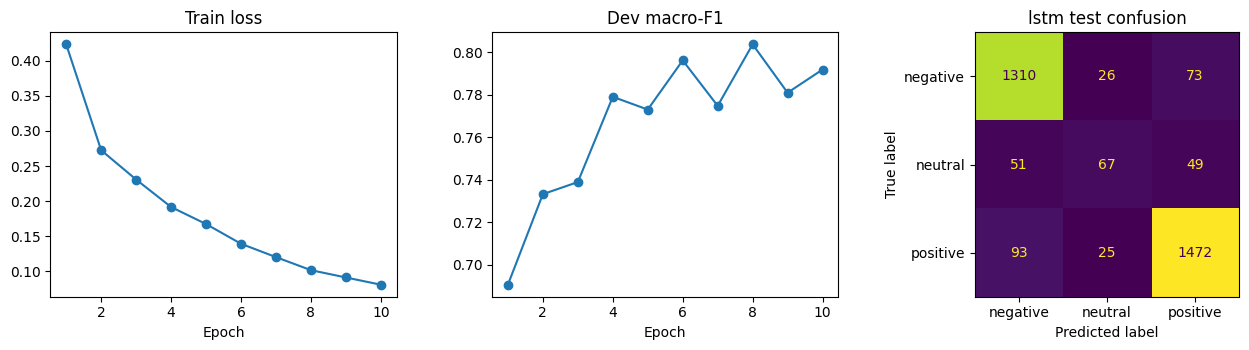

In [12]:
seed_all()
lstm = TextClassifier('LSTM').to(device)
lstm_history = fit_cls(lstm, 'lstm')
_, lstm_true, lstm_pred = evaluate_cls(lstm, test_loader)

rows = [cls_metrics('LSTM', lstm_true, lstm_pred, lstm, lstm_history),
        cls_metrics('TF-IDF', test_y, base_pred)]

print(pd.DataFrame(rows).to_string(index=False))
print(classification_report(lstm_true, lstm_pred, target_names=LABELS, digits=4, zero_division=0))
plot_cls(lstm_history, lstm_true, lstm_pred, 'lstm')

### **Nhận xét Bài 1 — LSTM 5 lớp**

Theo kết quả đã lưu, checkpoint tốt nhất xuất hiện ở **epoch 8**, với **dev macro-F1 = 0,8036**. Trên test, mô hình đạt **accuracy = 0,8999**, **precision-macro = 0,7974**, **recall-macro = 0,7522** và **F1-macro = 0,7700**, cao hơn TF-IDF (**0,6483**) về test macro-F1. LSTM có **3.138.007 tham số**, thời gian trung bình khoảng **6,50 giây/epoch** trên môi trường chạy đã ghi nhận.

Ở từng lớp, F1 của **negative = 0,9151**, **positive = 0,9246**, nhưng **neutral = 0,4702**. Lớp neutral khó nhận diện hơn và kéo macro-F1 xuống, dù accuracy gần 90%. Loss train tiếp tục giảm đến epoch 10, trong khi dev F1 cao nhất ở epoch 8 và dao động sau đó; vì thế chọn checkpoint bằng dev là hợp lý hơn lấy trọng số epoch cuối.

In [13]:
# Phân tích tối thiểu 3 trường hợp dự đoán sai trên DEV
_, true_dev, pred_dev = evaluate_cls(lstm, dev_loader)
lstm_errors = pd.DataFrame([dict(sentence=vsfc['dev'][i]['sentence'],
                                 true=LABELS[t], pred=LABELS[p])
    for i, (t,p) in enumerate(zip(true_dev, pred_dev)) if t != p])
print(lstm_errors.head(3).to_string(index=False))

                                                         sentence     true     pred
                        em không có bất cứ một lời phê bình nào .  neutral negative
thầy cho tự tìm hiểu , và tự tìm hiểu khác với hiểu được vấn đề .  neutral positive
                  cô dạy đều , bao giờ cũng đến sớm và đúng giờ . positive  neutral


### **Phân tích ba trường hợp dự đoán sai trên dev — LSTM**
1. Neutral → Negative: Câu “em không có bất cứ một lời phê bình nào .” được gán nhãn thật neutral nhưng mô hình dự đoán negative. Cấu trúc phủ định chứa từ mang sắc thái tiêu cực như “không” và “phê bình”; nếu mô hình đặt trọng số quá mạnh lên các tín hiệu cục bộ này, nó có thể không nắm được rằng toàn câu đang phủ nhận lời phê bình. Đây là giả thuyết giải thích, không phải kết luận về trọng số nội bộ.

2. Neutral → Positive: Câu “thầy cho tự tìm hiểu , và tự tìm hiểu khác với hiểu được vấn đề .” có nhãn neutral nhưng bị dự đoán positive. Cụm “tự tìm hiểu” có thể là tín hiệu dễ bị gắn với cách học chủ động; tuy vậy, nội dung tổng thể mang sắc thái phân biệt giữa tự tìm hiểu và thật sự hiểu bài, không thể hiện đánh giá tích cực rõ ràng. Trường hợp này phản ánh khó khăn khi xác định cảm xúc dựa trên ý nghĩa toàn câu.

3. Positive → Neutral: Câu “cô dạy đều , bao giờ cũng đến sớm và đúng giờ .” được gán positive nhưng mô hình dự đoán neutral. Nhận xét tích cực trong câu được biểu đạt gián tiếp qua tính chuyên cần và đúng giờ, không dựa trên các từ khen ngợi điển hình như “hay” hoặc “tốt”; vì vậy mô hình có thể xử lý như mô tả trung tính.

Cả ba trường hợp đều liên quan đến lớp neutral ở nhãn thật hoặc dự đoán. Điều này nhất quán với F1 neutral = 0,4702 trên test, cho thấy ranh giới ngữ nghĩa của lớp trung tính vẫn là điểm yếu đáng chú ý của mô hình.

## **Bài 2. Xây dựng mạng GRU gồm 5 lớp với hidden size là 256 cho bài toán phân loại văn bản. Huấn luyện mô hình này trên bộ dữ liệu UIT-VSFC (Vietnamese Student Feedback Corpus) sử dụng Adam làm phương thức tối ưu tham số và đánh giá độ hiệu quả của mô hình sử dụng độ đo F1.**

In [14]:
seed_all()
gru = TextClassifier('GRU').to(device)
gru_history = fit_cls(gru, 'gru')

_, gru_true, gru_pred = evaluate_cls(gru, test_loader)
rows.insert(1, cls_metrics('GRU', gru_true, gru_pred, gru, gru_history))

comparison = pd.DataFrame(rows)
print(comparison.to_string(index=False))

gru 1/10: loss=0.3945, dev F1=0.6968
gru 2/10: loss=0.2636, dev F1=0.7397
gru 3/10: loss=0.2161, dev F1=0.7662
gru 4/10: loss=0.1808, dev F1=0.7674
gru 5/10: loss=0.1534, dev F1=0.7786
gru 6/10: loss=0.1293, dev F1=0.7740
gru 7/10: loss=0.1056, dev F1=0.7808
gru 8/10: loss=0.0928, dev F1=0.7817
gru 9/10: loss=0.0766, dev F1=0.7852
gru 10/10: loss=0.0683, dev F1=0.7843
 model  accuracy  precision_macro  recall_macro  f1_macro  parameters  seconds_per_epoch  best_epoch
  LSTM  0.899874         0.797407      0.752240  0.769974   3138007.0           6.501292         8.0
   GRU  0.903664         0.788304      0.749505  0.764962   2468823.0           5.757225         9.0
TF-IDF  0.889766         0.810264      0.647004  0.648318         NaN                NaN         NaN


GRU đạt **dev macro-F1 tốt nhất = 0,7852 ở epoch 9**, và **test macro-F1 = 0,7650**. GRU có **2.468.823 tham số**, mất trung bình khoảng **5,76 giây/epoch**, ít hơn LSTM (**3.138.007 tham số; 6,50 giây/epoch**). GRU đạt **accuracy = 0,9037** so với LSTM **0,8999**, nhưng LSTM nhỉnh hơn nhẹ ở **macro-F1** (**0,7700 so với 0,7650**).

              precision    recall  f1-score   support

    negative     0.9062    0.9326    0.9192      1409
     neutral     0.5289    0.3832    0.4444       167
    positive     0.9298    0.9327    0.9312      1590

    accuracy                         0.9037      3166
   macro avg     0.7883    0.7495    0.7650      3166
weighted avg     0.8981    0.9037    0.9002      3166

F1 từng lớp:
      class      LSTM       GRU    TF-IDF
0  negative  0.915124  0.919203  0.906437
1   neutral  0.470175  0.444444  0.119565
2  positive  0.924623  0.931240  0.918953


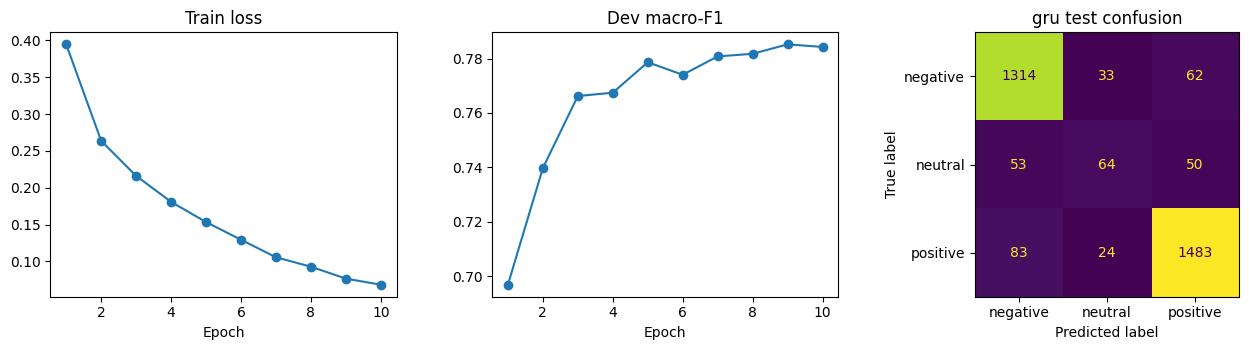

In [15]:
print(classification_report(gru_true, gru_pred, target_names=LABELS, digits=4, zero_division=0))
print('F1 từng lớp:')
print(pd.DataFrame({'class': LABELS, **{
    name: f1_score(test_y, pred, labels=[0,1,2], average=None, zero_division=0)
    for name, pred in [('LSTM', lstm_pred), ('GRU', gru_pred), ('TF-IDF', base_pred)]}}))

plot_cls(gru_history, gru_true, gru_pred, 'gru')

### **Phân tích F1 từng lớp — ba mô hình sentiment**
Ở lớp negative, F1 lần lượt là TF-IDF 0,9064, LSTM 0,9151 và GRU 0,9192; lớp positive lần lượt là 0,9190, 0,9246, 0,9312. Cả ba mô hình đều nhận diện khá tốt hai cực tính cảm xúc. GRU nhỉnh hơn LSTM ở cả negative và positive, góp phần lý giải accuracy cao hơn của GRU.

Ngược lại, lớp neutral có F1 rất thấp với TF-IDF (0,1196), được cải thiện đáng kể nhờ LSTM (0,4702) và GRU (0,4444) nhưng vẫn yếu hơn hai lớp còn lại. LSTM vượt GRU khoảng 0,0257 F1 ở neutral, đủ để tạo lợi thế nhỏ về macro-F1 chung mặc dù GRU vượt ở hai lớp kia. Kết quả thể hiện rõ vai trò của macro-F1: một mô hình không nên được đánh giá chỉ dựa trên hai lớp chiếm đa số.

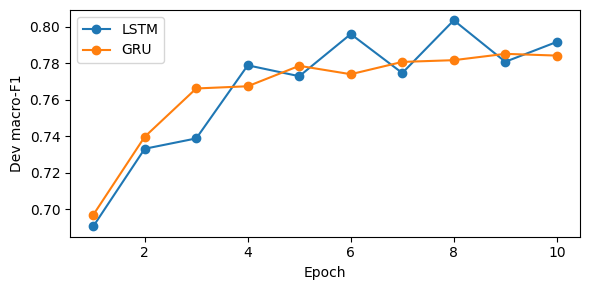

In [16]:
plt.figure(figsize=(6,3))
for name, hist in [('LSTM', lstm_history), ('GRU', gru_history)]:
    plt.plot(hist.epoch, hist.dev_f1, marker='o', label=name)

plt.xlabel('Epoch')
plt.ylabel('Dev macro-F1')
plt.legend()
plt.tight_layout()
plt.show()

## **Bài 3. Xây dựng kiến trúc Encoder trong đó Encoder gồm 5 lớp BiLSTM với hidden size là 256 cho bài toán nhận diện thực thể (Name Entity Recognition). Huấn luyện mô hình trên bộ dữ liệu PhoNER và đánh giá độ hiệu quả của mô hình sử dụng độ đo F1.**

PhoNER là bài toán gán nhãn từng token theo lược đồ BIO, khác với phân loại một nhãn cho cả câu trên UIT-VSFC. BiLSTM khai thác ngữ cảnh trái và phải của mỗi token; với hidden size 256 trên mỗi chiều, đặc trưng tại mỗi vị trí có 512 chiều trước khi qua lớp phân loại 21 nhãn. Packing và ignore_index=-100 giúp không tính các vị trí đệm như token hợp lệ.

Metric được dùng là entity micro-F1 strict IOB2: một thực thể chỉ được coi là đúng khi có cùng loại và cùng ranh giới. Vì đơn vị chấm là thực thể thay vì câu, điểm entity-F1 của BiLSTM không được dùng để xếp hạng trực tiếp cùng macro-F1 của TF-IDF, LSTM và GRU.

In [17]:
ner = {}
for split in ['train', 'dev', 'test']:
    path = DATA / 'phoner' / f'{split}_syllable.json'
    records = []

    with open(path, 'r', encoding='utf-8-sig') as f:
        for line in f:
            if line.strip():
                record = json.loads(line)
                records.append(record)
    ner[split] = records

In [18]:
train_words = []
for record in ner['train']:
    words = record['words']
    train_words.append(words)

ner_vocab = build_vocab(train_words)
unique_tags = set()
for record in ner['train']:
    for tag in record['tags']:
        unique_tags.add(tag)

TAGS = sorted(unique_tags)
tag_to_id = {}

for i, tag in enumerate(TAGS):
    tag_to_id[tag] = i

In [19]:
def ner_rows(split):
    rows = []
    for record in ner[split]:
        words = record['words']
        tags = record['tags']
        token_ids = encode(words, ner_vocab)

        tag_ids = []
        for tag in tags:
            tag_id = tag_to_id[tag]
            tag_ids.append(tag_id)

        rows.append((token_ids, tag_ids))
    return rows

In [20]:
def collate_ner(batch):
    x = []
    y = []
    lengths = []
    for token_ids, tag_ids in batch:
        token_tensor = torch.tensor(token_ids, dtype=torch.long)
        tag_tensor = torch.tensor(tag_ids, dtype=torch.long)

        x.append(token_tensor)
        y.append(tag_tensor)
        lengths.append(len(token_ids))

    x = pad_sequence(x, batch_first=True, padding_value=PAD)
    y = pad_sequence(y, batch_first=True, padding_value=PAD_TAG)

    lengths = torch.tensor(lengths, dtype=torch.long)
    return x, lengths, y

In [21]:
def ner_loader(split, shuffle=False):
    rows = ner_rows(split)
    loader = DataLoader(dataset=rows,
                        batch_size=cfg['batch'],
                        shuffle=shuffle,
                        collate_fn=collate_ner,
                        generator=torch.Generator().manual_seed(42))
    return loader

ner_train_loader = ner_loader('train', shuffle=True)
ner_dev_loader = ner_loader('dev', shuffle=False)
ner_test_loader = ner_loader('test', shuffle=False)

In [22]:
print('PhoNER:')
print('Train:', len(ner['train']))
print('Dev:', len(ner['dev']))
print('Test:', len(ner['test']))
print('Number of tags:', len(TAGS))

x, lengths, y = next(iter(ner_train_loader))

print('Input shape:', x.shape)
print('Lengths shape:', lengths.shape)
print('Labels shape:', y.shape)

PhoNER:
Train: 5027
Dev: 2000
Test: 3000
Number of tags: 21
Input shape: torch.Size([32, 62])
Lengths shape: torch.Size([32])
Labels shape: torch.Size([32, 62])


Output đã lưu xác nhận 5.027 train, 2.000 dev, 3.000 test và 21 nhãn BIO. Một batch minh họa có shape input/labels (32, 62); đây là chiều dài sau padding động của batch đó, không phải giới hạn độ dài cố định cho toàn bộ dữ liệu. PAD_TAG=-100 giúp CrossEntropyLoss(ignore_index=-100) không tính loss ở vị trí đệm.

Trước khi train, nên xác nhận mọi câu có cùng số lượng words và tags, vì lệch độ dài sẽ làm nhãn không khớp với token.

In [23]:
class TokenTagger(nn.Module):
    def __init__(self):
        super().__init__()
        self.emb = nn.Embedding(len(ner_vocab), cfg['emb'], padding_idx=PAD)
        self.rnn = nn.LSTM(cfg['emb'], cfg['hidden'], cfg['layers'],
                           batch_first=True, bidirectional=True, dropout=cfg['dropout'])
        self.drop = nn.Dropout(cfg['dropout'])
        self.fc = nn.Linear(2*cfg['hidden'], len(TAGS))

    def forward(self, ids, lengths):
        packed = pack_padded_sequence(self.emb(ids), lengths.cpu(),
                                      batch_first=True, enforce_sorted=False)
        output, _ = self.rnn(packed)
        output, _ = pad_packed_sequence(output, batch_first=True, total_length=ids.size(1))
        return self.fc(self.drop(output))

In [24]:
def evaluate_ner(model, loader):
    model.eval()
    true, pred = [], []
    with torch.no_grad():
        for ids, lengths, labels in loader:
            ids = ids.to(device)
            logits = model(ids, lengths)
            predicted_ids = torch.argmax(logits, dim=-1)
            predicted_ids = predicted_ids.cpu()

            for i in range(len(lengths)):
                length = int(lengths[i])
                actual_tags, predicted_tags = [], []

                for j in range(length):
                    actual_id = int(labels[i][j])
                    predicted_id = int(predicted_ids[i][j])
                    actual_tags.append(TAGS[actual_id])
                    predicted_tags.append(TAGS[predicted_id])

                true.append(actual_tags)
                pred.append(predicted_tags)

    score = entity_f1(true, pred, mode='strict', scheme=IOB2, zero_division=0)
    return score, true, pred

def fit_ner(model):
    optimizer = torch.optim.Adam(model.parameters(), lr=cfg['lr'])
    criterion = nn.CrossEntropyLoss(ignore_index=PAD_TAG)
    best_f1 = -1
    best_state = None
    history = []

    for epoch in range(1, cfg['epochs'] + 1):
        model.train()
        start = time.perf_counter()
        total_loss, token_count = 0, 0

        for ids, lengths, labels in ner_train_loader:
            ids = ids.to(device)
            labels = labels.to(device)

            optimizer.zero_grad(set_to_none=True)
            logits = model(ids, lengths).reshape(-1, len(TAGS))
            labels = labels.reshape(-1)

            loss = criterion(logits, labels)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            optimizer.step()

            total_loss += loss.item() * (labels != PAD_TAG).sum().item()
            token_count += (labels != PAD_TAG).sum().item()

        if device.type == 'cuda':
            torch.cuda.synchronize()

        seconds = time.perf_counter() - start
        avg_loss = total_loss / token_count
        dev_f1, _, _ = evaluate_ner(model, ner_dev_loader)
        history.append({'epoch': epoch, 'loss': avg_loss, 'dev_f1': dev_f1, 'seconds': seconds})

        if dev_f1 > best_f1:
            best_f1 = dev_f1
            best_state = copy.deepcopy(model.state_dict())
        print(f'BiLSTM {epoch}/{cfg["epochs"]}: 'f'loss={avg_loss:.4f}, 'f'dev entity-F1={dev_f1:.4f}')

    model.load_state_dict(best_state)
    model.eval()
    torch.save(best_state, ART / 'bilstm_ner.pt')
    return pd.DataFrame(history)

BiLSTM xuất logits cho mỗi token với 21 nhãn; loss chỉ được tính trên các token thật, tránh để độ dài padding làm sai lệch quá trình học. Checkpoint được chọn theo entity-F1 trên dev chứ không theo token accuracy. Cách lựa chọn này phù hợp với mục tiêu thực tế: dự đoán đúng trọn vẹn loại và ranh giới thực thể, không chỉ đúng nhiều vị trí nhãn O.

BiLSTM 1/10: loss=0.7545, dev entity-F1=0.5534
BiLSTM 2/10: loss=0.1889, dev entity-F1=0.8255
BiLSTM 3/10: loss=0.0969, dev entity-F1=0.8526
BiLSTM 4/10: loss=0.0661, dev entity-F1=0.8832
BiLSTM 5/10: loss=0.0482, dev entity-F1=0.8836
BiLSTM 6/10: loss=0.0373, dev entity-F1=0.8881
BiLSTM 7/10: loss=0.0324, dev entity-F1=0.8866
BiLSTM 8/10: loss=0.0277, dev entity-F1=0.8903
BiLSTM 9/10: loss=0.0222, dev entity-F1=0.8994
BiLSTM 10/10: loss=0.0172, dev entity-F1=0.9034
     model  precision  recall  entity_micro_f1  parameters  seconds_per_epoch  best_epoch
BiLSTM NER   0.901102 0.88513         0.893044     8305297           7.423266          10
                     precision    recall  f1-score   support

                AGE     0.9456    0.9261    0.9358       582
               DATE     0.9628    0.9547    0.9587      1654
             GENDER     0.9483    0.9134    0.9305       462
                JOB     0.6167    0.4277    0.5051       173
           LOCATION     0.9053    0.9020   

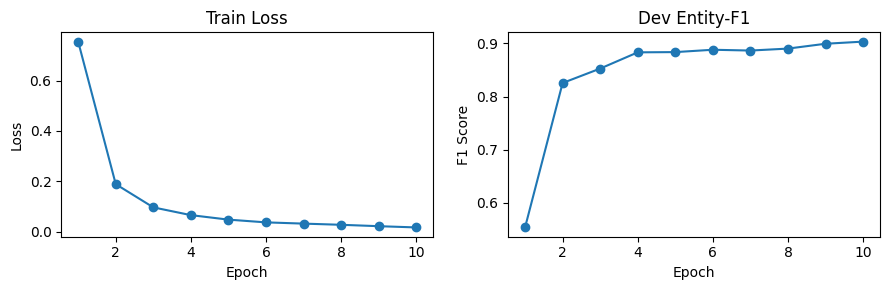

In [25]:
seed_all()
tagger = TokenTagger().to(device)
ner_history = fit_ner(tagger)

dev_f1, ner_dev_true, ner_dev_pred = evaluate_ner(tagger, ner_dev_loader)
ner_f1, ner_true, ner_pred = evaluate_ner(tagger, ner_test_loader)

precision = entity_precision(ner_true, ner_pred, mode='strict', scheme=IOB2, zero_division=0)
recall = entity_recall(ner_true, ner_pred, mode='strict', scheme=IOB2, zero_division=0)
parameters = sum(p.numel() for p in tagger.parameters())
seconds_per_epoch = ner_history['seconds'].mean()
best_index = ner_history['dev_f1'].idxmax()
best_epoch = int(ner_history.loc[best_index, 'epoch'])

ner_result = pd.DataFrame([{'model': 'BiLSTM NER',
                            'precision': precision,
                            'recall': recall,
                            'entity_micro_f1': ner_f1,
                            'parameters': parameters,
                            'seconds_per_epoch': seconds_per_epoch,
                            'best_epoch': best_epoch}])
print(ner_result.to_string(index=False))
report = entity_report(ner_true, ner_pred, mode='strict', scheme=IOB2, digits=4, zero_division=0)
print(report)


fig, axes = plt.subplots(1, 2, figsize=(9, 3))
axes[0].plot(ner_history['epoch'], ner_history['loss'], marker='o')
axes[0].set_title('Train Loss')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')

axes[1].plot(ner_history['epoch'], ner_history['dev_f1'],marker='o')
axes[1].set_title('Dev Entity-F1')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('F1 Score')

plt.tight_layout()
plt.show()

### **Phân tích kết quả Bài 3 — BiLSTM NER 5 lớp**

**Quá trình học.** Train loss giảm mạnh từ 0,7545 (epoch 1) xuống 0,0172 (epoch 10). Dev entity-F1 tăng từ 0,5534 lên 0,9034, và giá trị cao nhất xuất hiện ở epoch 10. Dù dev F1 có giảm nhẹ ở epoch 7 (từ 0,8881 xuống 0,8866), xu hướng chung vẫn tăng. Trong 10 epoch đã chạy, chưa có xu hướng suy giảm kéo dài của dev F1 đủ để khẳng định overfitting; đồng thời cũng không có bằng chứng rằng huấn luyện thêm sẽ chắc chắn cải thiện.

**Hiệu năng test.** Checkpoint đã chọn đạt entity precision = 0,9011, entity recall = 0,8851, entity micro-F1 = 0,8930. Precision cao hơn recall khoảng 0,0160, cho thấy mô hình có xu hướng bỏ sót một số thực thể so với lượng thực thể dự đoán đúng. BiLSTM có 8.305.297 tham số, trung bình 7,42 giây/epoch trong lần chạy.

**Theo loại thực thể.** DATE (F1 = 0,9587), PATIENT_ID (0,9465), AGE (0,9358) và GENDER (0,9305) là các nhóm được nhận diện tốt. LOCATION đạt 0,9037 với 4.441 thực thể thật, đóng góp lớn vào tổng điểm micro-F1. Ngược lại, JOB (0,5051; recall 0,4277) và NAME (0,6512; recall 0,6164) còn yếu, cho thấy hệ thống khó bao phủ đầy đủ các thực thể thuộc hai nhóm này. Vì micro-F1 chịu ảnh hưởng nhiều từ nhóm có hỗ trợ lớn, báo cáo riêng F1 theo loại thực thể giúp phản ánh đầy đủ hơn các hạn chế này.

In [26]:
errors = []
for i in range(len(ner_dev_true)):
    gold_tags = ner_dev_true[i]
    pred_tags = ner_dev_pred[i]

    actual_entities = set(get_entities(gold_tags))
    predicted_entities = set(get_entities(pred_tags))
    wrong_entities = actual_entities - predicted_entities

    for entity in wrong_entities:
        entity_type, start, end = entity
        overlap = []
        for pred_type, pred_start, pred_end in predicted_entities:
            if pred_start <= end and start <= pred_end:
                overlap.append((pred_type, pred_start, pred_end))

        if len(overlap) == 0:
            kind = 'Bỏ sót thực thể'
        else:
            wrong_type = False

            for pred_type, pred_start, pred_end in overlap:
                if pred_start == start and pred_end == end:
                    if pred_type != entity_type:
                        wrong_type = True
            if wrong_type:
                kind = 'Sai loại thực thể'
            else:
                kind = 'Sai ranh giới thực thể'

        sentence = ' '.join(ner['dev'][i]['words'])
        errors.append({'kind': kind, 'sentence': sentence, 'gold': f'{entity_type}:{start}-{end}', 'pred': str(overlap)})

errors = pd.DataFrame(errors, columns=['kind', 'sentence', 'gold', 'pred'])
print('Thống kê lỗi DEV:')
print(errors['kind'].value_counts())
error_types = [
    'Bỏ sót thực thể',
    'Sai ranh giới thực thể',
    'Sai loại thực thể'
]

for kind in error_types:
    subset = errors[errors['kind'] == kind]
    print(f'\n{kind}:')
    if len(subset) > 0:
        print(subset.head(1).to_string(index=False))
    else:
        print('Không tìm thấy lỗi loại này trên DEV')

Thống kê lỗi DEV:
kind
Bỏ sót thực thể           317
Sai ranh giới thực thể    308
Sai loại thực thể         139
Name: count, dtype: int64

Bỏ sót thực thể:
           kind                                                                                                                                                                                        sentence                      gold pred
Bỏ sót thực thể Bác sĩ Nguyễn Trung Nguyên , Giám đốc Trung tâm Chống độc , Bệnh viện Bạch Mai , cho biết bệnh nhân được chuyển đến bệnh viện ngày 7/3 , chẩn đoán ngộ độc thuốc điều trị sốt rét chloroquine . SYMPTOM_AND_DISEASE:32-34   []

Sai ranh giới thực thể:
                  kind                                                                                                                                                                                                       sentence      gold              pred
Sai ranh giới thực thể " Bệnh nhân 812 " , nam , 62 tuổi , là nhân viên giao bánh 

### **Phân tích ba nhóm lỗi NER trên dev**

Việc đối chiếu các thực thể thật với các thực thể dự đoán trên dev thu được **317 lần bỏ sót thực thể**, **308 lần sai ranh giới** và **139 lần sai loại**. Trong tổng số **764 lượt thực thể thật bị dự đoán sai** được phân vào ba nhóm, bỏ sót chiếm khoảng **41,5%**, sai ranh giới **40,3%** và sai loại **18,2%**. Như vậy, vấn đề nổi bật không chỉ là nhầm loại mà còn là **không phát hiện đủ thực thể hoặc xác định sai phạm vi**.

- **Bỏ sót (317):** Ở ví dụ dev hiển thị ngay phía trên, một thực thể `SYMPTOM_AND_DISEASE` có nhãn thật nhưng không có thực thể dự đoán chồng lấn (`pred=[]`). Đây là trường hợp mô hình không nhận ra một thực thể tồn tại trong câu.
- **Sai ranh giới (308):** Một thực thể `JOB` được gán vị trí thật **43–46** nhưng mô hình chỉ dự đoán **44–46**. Mô hình phát hiện đúng loại nhưng bỏ mất token đầu, nên vẫn bị tính sai toàn bộ thực thể trong đánh giá strict IOB2.
- **Sai loại (139):** Một thực thể thật `ORGANIZATION` ở vị trí **28–31** bị dự đoán thành `LOCATION` với ranh giới giữ nguyên. Ví dụ cho thấy ngữ cảnh chứa tên cơ sở/tổ chức có thể gây nhầm lẫn với địa điểm.

Các ví dụ này là **ba trường hợp lỗi thực tế được cell trước trích từ dev**; không sao chép lại nguyên câu PhoNER vào phần nhận xét để tránh phát tán dữ liệu. Thống kê tính theo **thực thể thật bị dự đoán sai**, không phải số câu, và chưa bao gồm các false positive hoàn toàn không khớp thực thể thật.

### **Bảng tổng hợp kết quả**

Ba mô hình **TF-IDF, LSTM, GRU** sử dụng macro-F1 phân loại cảm xúc; **BiLSTM NER** sử dụng entity micro-F1 strict IOB2, **không so sánh trực tiếp** với ba mô hình phân loại. Thời gian của TF-IDF là tổng thời gian fit, không phải giây/epoch.

In [28]:
lstm_row = comparison.loc[comparison['model'] == 'LSTM'].iloc[0]
gru_row = comparison.loc[comparison['model'] == 'GRU'].iloc[0]

summary = pd.DataFrame([
    {
        'Mô hình': 'TF-IDF + Logistic Regression',
        'Dev F1 tốt nhất': baseline_dev_f1,
        'Test F1': f1_score(test_y, base_pred, labels=[0, 1, 2],
                            average='macro', zero_division=0),
        'Tham số': 'TF-IDF (1–2 grams)',
        'Giây/epoch': f'{baseline_fit_seconds:.2f} (fit)'
    },
    {
        'Mô hình': 'LSTM 5 lớp',
        'Dev F1 tốt nhất': lstm_history['dev_f1'].max(),
        'Test F1': lstm_row['f1_macro'],
        'Tham số': int(lstm_row['parameters']),
        'Giây/epoch': f"{lstm_history['seconds'].mean():.2f}"
    },
    {
        'Mô hình': 'GRU 5 lớp',
        'Dev F1 tốt nhất': gru_history['dev_f1'].max(),
        'Test F1': gru_row['f1_macro'],
        'Tham số': int(gru_row['parameters']),
        'Giây/epoch': f"{gru_history['seconds'].mean():.2f}"
    },
    {
        'Mô hình': 'BiLSTM NER 5 lớp',
        'Dev F1 tốt nhất': ner_history['dev_f1'].max(),
        'Test F1': ner_result['entity_micro_f1'].iloc[0],
        'Tham số': int(ner_result['parameters'].iloc[0]),
        'Giây/epoch': f"{ner_history['seconds'].mean():.2f}"
    }
])

print('Bảng tổng hợp kết quả cần nộp')
display(
    summary.style
    .format({'Dev F1 tốt nhất': '{:.4f}', 'Test F1': '{:.4f}',
             'Tham số': lambda x: f'{x:,}' if isinstance(x, (int, np.integer)) else x})
    .set_table_styles([
        {'selector': 'th', 'props': [('background-color', '#dce5f1'),
                                    ('color', '#111827'), ('text-align', 'center'),
                                    ('border', '1px solid #555')]},
        {'selector': 'td', 'props': [('border', '1px solid #555'),
                                    ('padding', '8px')]}
    ])
    .hide(axis='index')
)
summary.to_csv(ART / 'summary_results.csv', index=False)
print('Đã lưu:', ART / 'summary_results.csv')

Bảng tổng hợp kết quả cần nộp


Mô hình,Dev F1 tốt nhất,Test F1,Tham số,Giây/epoch
TF-IDF + Logistic Regression,0.6894,0.6483,TF-IDF (1–2 grams),2.42 (fit)
LSTM 5 lớp,0.8036,0.7700,"3,138,007",6.50
GRU 5 lớp,0.7852,0.7650,"2,468,823",5.76
BiLSTM NER 5 lớp,0.9034,0.8930,"8,305,297",7.42


Đã lưu: artifacts/summary_results.csv


### **Kết luận chung từ thực nghiệm**

**Với phân loại cảm xúc**, cả LSTM và GRU đều cải thiện rõ rệt so với TF-IDF (**test macro-F1: 0,7700 và 0,7650 so với 0,6483**). LSTM đạt macro-F1 cao hơn GRU khoảng **0,0050**, chủ yếu nhờ nhận diện lớp neutral tốt hơn; GRU lại có accuracy nhỉnh hơn và chi phí thấp hơn khoảng **21,3% tham số**, **11,4% thời gian/epoch**. Do chênh lệch F1 khá nhỏ và chỉ có một seed, kết quả nên được hiểu là đánh đổi chất lượng–chi phí của lần thử nghiệm này, không phải kết luận kiến trúc nào luôn vượt trội.

**Điểm yếu chính của sentiment** là lớp `neutral`: F1 chỉ **0,1196** ở TF-IDF, **0,4702** ở LSTM và **0,4444** ở GRU, thấp hơn đáng kể so với negative và positive. Ba ví dụ dự đoán sai trên dev củng cố nhận định rằng cách biểu đạt cảm xúc phủ định, gián tiếp hoặc thiếu từ chỉ sắc thái rõ ràng dễ gây nhầm lẫn.

**Với NER**, BiLSTM đạt **test entity micro-F1 = 0,8930** và dev entity-F1 cao nhất **0,9034 tại epoch 10**. Mô hình hoạt động tốt trên DATE/PATIENT_ID nhưng còn yếu với JOB/NAME. Thống kê **317 bỏ sót**, **308 sai ranh giới** và **139 sai loại** cho thấy ưu tiên cải thiện khả năng phát hiện đầy đủ và xác định ranh giới thực thể.

**Giới hạn của nhận xét:** các số liệu phản ánh output của một lần chạy hiện có; chưa có thí nghiệm nhiều seed hoặc kiểm định độ biến thiên. Không nên diễn giải sự khác biệt nhỏ giữa LSTM và GRU thành kết luận tổng quát. Điểm F1 của bài NER không được so sánh số học trực tiếp với macro-F1 của bài sentiment.